In [142]:
######################################################################################################
# ALUNO : Daniel Marques Diniz Maia
# MATRÍCULA : 2026061836
# TURMA : TM
######################################################################################################

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter as savgol

def ruido(y):
    return y + y*0.004*(1-2*np.random.random(size=len(y)))

def plot_derivada(x, y, ord):
    '''
    Função única que recebe o domínio e uma função que deseja-se derivar ord vezes que retorna todos os gráficos de uma vez.
    Parâmetros:
    x - domínio a ser analisado. O incremento de derivação será gerado por plot_derivada. TIPO: array-like
    y - lei da função que deseja-se derivar. TIPO: array-like
    ord - quantas derivadas deseja-se fazer. TIPO: int
    '''
    dx = x[1]-x[0] # incremento de derivação
    y = ruido(y)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # Plot com suavização (deve ser feito antes do outro, pois y será alterada no loop)
    wl = int(0.1*len(x) + 1) # janela do Savitzky-Golay dinâmica, garantindo um bom ajuste em todas as curvas 
    y_suavz = savgol(y, window_length=wl, polyorder=4)
    axes[1].plot(x,y_suavz/np.abs(y_suavz).max(), label='Original suavizada')
    axes[1].set_title('Curvas com suavização')
    for d in range(1, ord + 1):
         # O argumento deriv=d calcula a d-ésima derivada suavizada diretamente
        dydxs = savgol(y, window_length=wl, polyorder=4, deriv=d, delta=dx)
        axes[1].plot(x, dydxs / np.abs(dydxs).max(), label=f'Der. de ordem {d}')
    # Plot sem suavização
    axes[0].plot(x,y/np.abs(y).max(), label='Original')
    axes[0].set_title('Curvas sem suavização')
    ordv=ord # precisaremos armazenar3 ord em outra variável
    while ordv>0:
        # Plot sem suavização
        dydx = np.gradient(y,dx)
        axes[0].plot(x,dydx/np.abs(dydx).max(), label=f'Der. de ordem {ord+1-ordv}')
        y = dydx
        ordv -= 1
    
    axes[0].legend()
    axes[1].legend()
    plt.show()

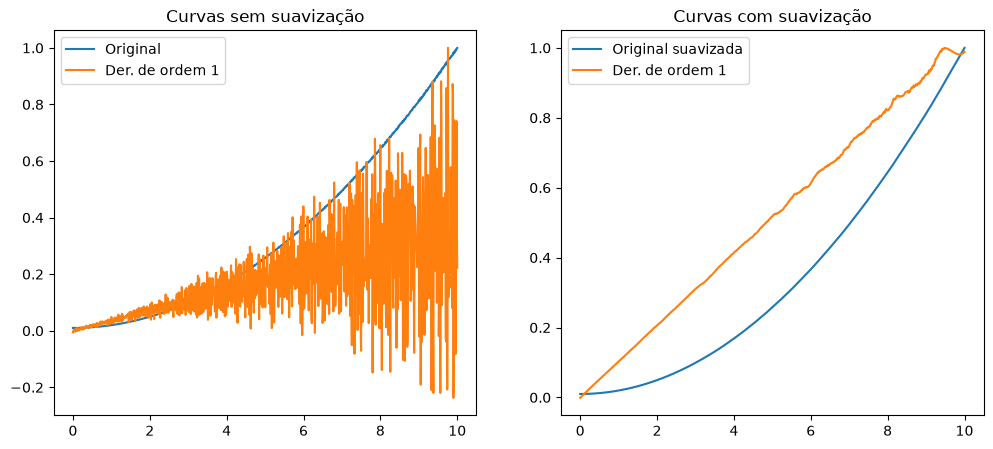

In [144]:
# Atividades para hoje 
#  1) Modifique cada um dos 6 exemplos acima, adicionando ruído
#  2) Faça a diferenciação, o que ocorre ?
#  3) Faça uma suavização dos dados experimentais e depois calcule as derivadas de primeira e segunda ordem !

# Exemplo 01

x1 = np.linspace(0,10,1000)
y1 = x1**2 + 1
plot_derivada(x1,y1,1)

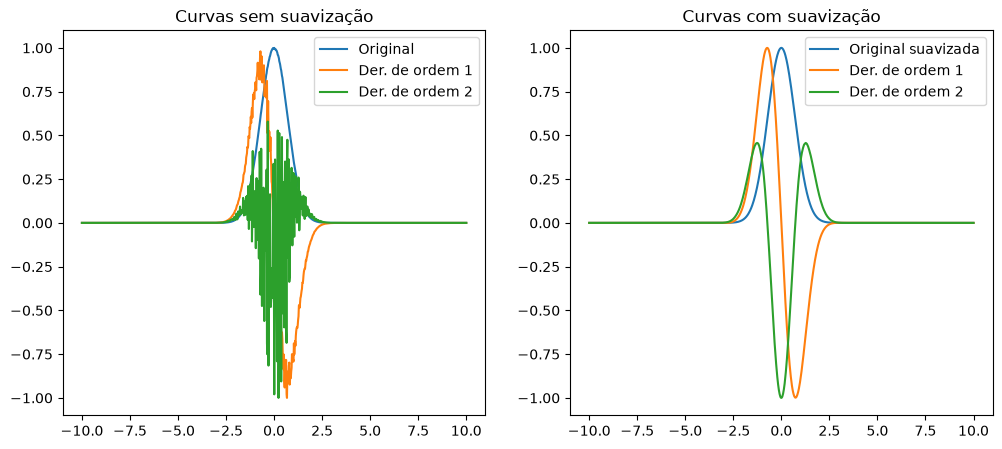

In [145]:
# Exemplo 02
x2 = np.linspace(-10,10,1000)
y2 = 2.0*np.exp(-x2**2)
plot_derivada(x2,y2,2)

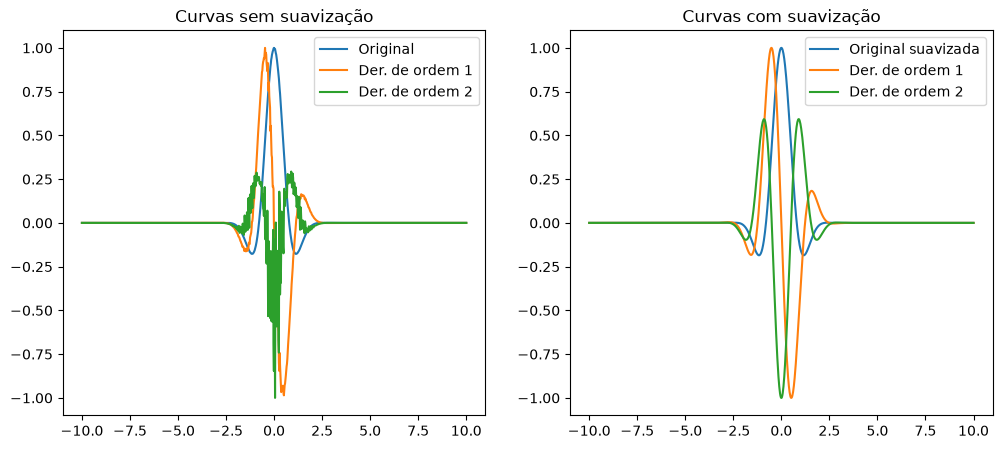

In [146]:
# Exemplo 3

x3 = np.linspace(-10,10,1000)
y3 = 2.0*np.exp(-x3**2)*np.cos(2*x3)
plot_derivada(x3,y3,2)

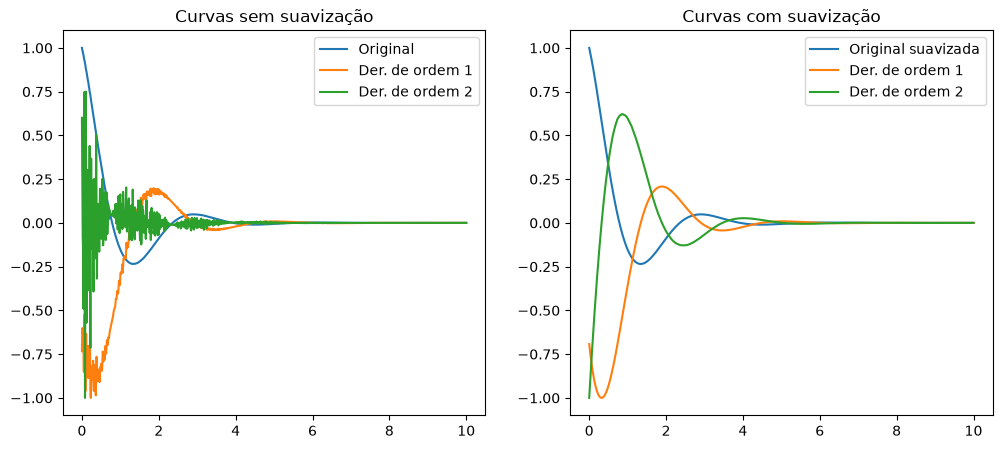

In [147]:
# Exemplo 4
x4 = np.linspace(0,10,1000)
y4 = 2.0*np.exp(-x4)*np.cos(2*x4)
plot_derivada(x4,y4,2)

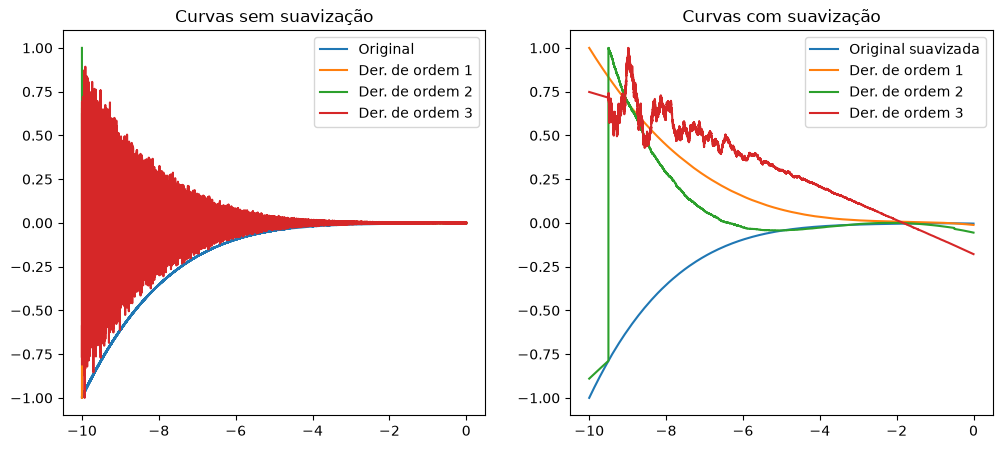

In [148]:
# Exemplo 5
x5 = np.linspace(-10,0,100000)
y5 = -3*(x5 + 2)**4 + 2*x5**3 - 3*(x5- 2)**2 + 4*x5 + 1
plot_derivada(x5,y5,3)
# Observe que as curvas sem suavização estão horríveis: a derivada de ordem 3 oscila tanto que parece preencher a aréa entre as outras curvas. Isso decorre do tamanho de x5.
# As com suavização sofrem muito do efeito de borda, e a der. de ordem 3 continua consideravelmente sensível a ruído.